# **Lab 7(B) - Mathematical and Statistical Filters**
---
### Name: Mohammed Feras Sawab

### ID: 2240009066
---

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

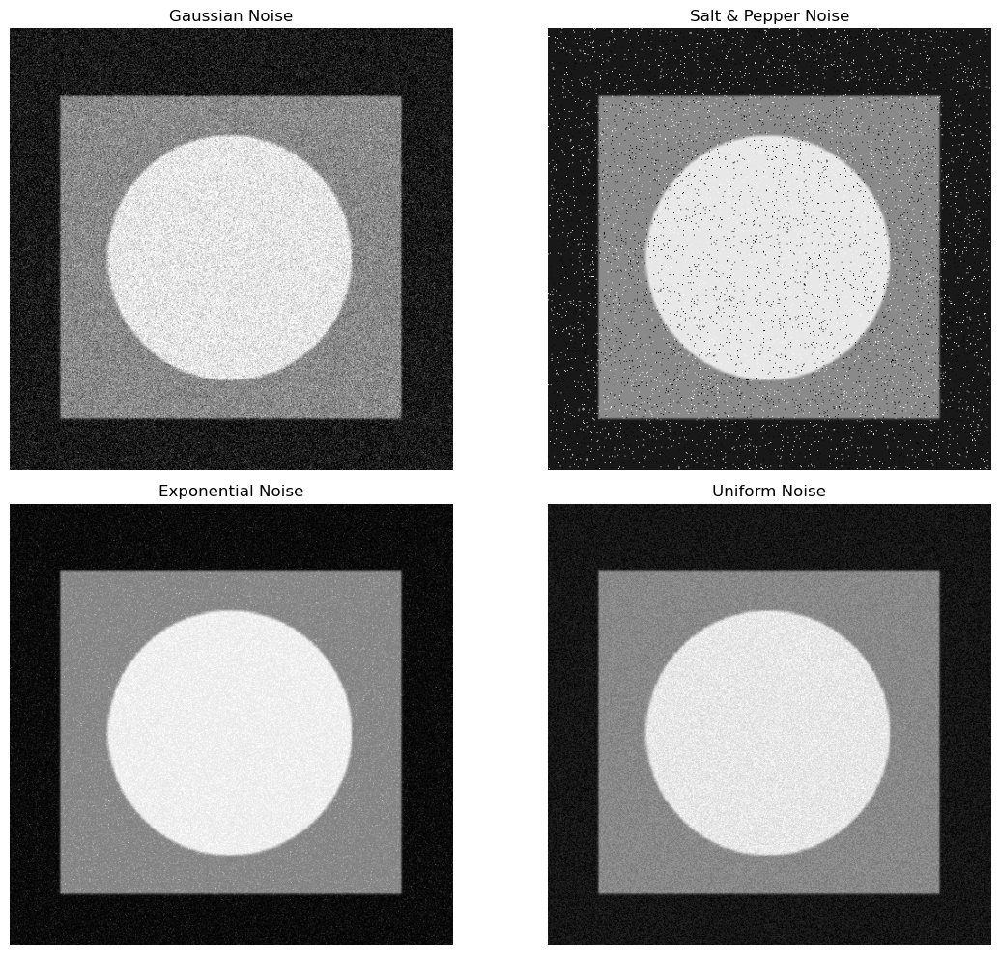

In [2]:
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
imgPath = 'noise.jpg'
img = cv2.imread(imgPath, 0)

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)



# 2. Load image in grayscale
img = cv2.imread(imgPath, 0)

# 3. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 4. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()


In [3]:
# --- METHOD 1: Using Built-in OpenCV function ---

# 2. Apply Arithmetic Mean Filter (using a 5x5 blur window)
# The larger the numbers in (3, 3), the smoother the image becomes.,
# you can change kernel size to (5,5), (7,7) etc.
filtered_img = cv2.blur(noise_gauss, (3, 3))

display(filtered_img)

array([[31, 23, 17, ..., 34, 35, 34],
       [32, 27, 18, ..., 24, 31, 31],
       [21, 22, 16, ..., 22, 24, 20],
       ...,
       [43, 40, 38, ..., 25, 35, 44],
       [44, 41, 30, ..., 19, 30, 37],
       [32, 25, 18, ..., 18, 33, 39]], shape=(506, 508), dtype=uint8)

In [4]:
# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(img, -1, kernel)

display(arithmetic_mean_manual)

array([[24, 24, 24, ..., 24, 24, 24],
       [24, 24, 24, ..., 24, 24, 24],
       [24, 24, 24, ..., 24, 24, 24],
       ...,
       [24, 24, 24, ..., 24, 24, 24],
       [24, 24, 24, ..., 24, 24, 24],
       [24, 24, 24, ..., 24, 24, 24]], shape=(506, 508), dtype=uint8)

## **Geometric Means**

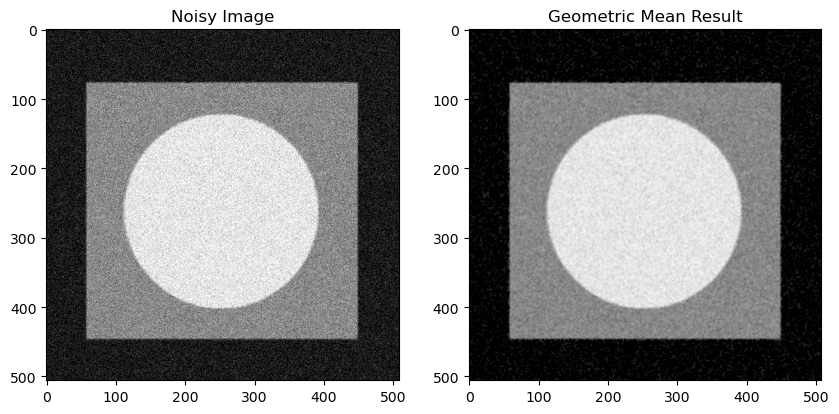

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('Geometric Mean Result')
plt.show()


## **Harmonic Means Filter**

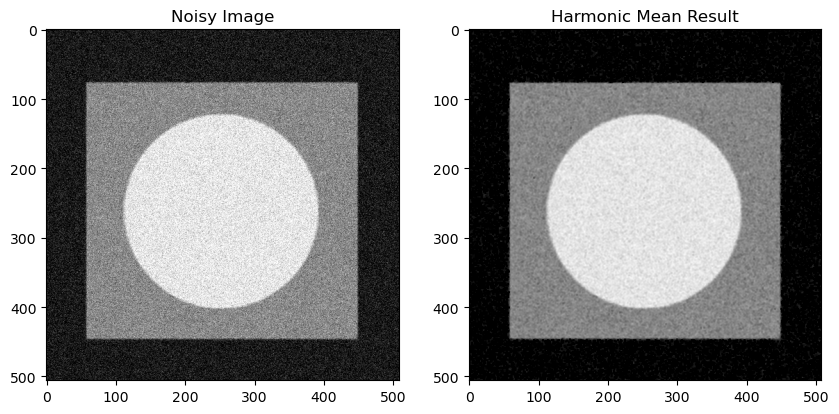

In [6]:

def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img, cmap='gray'), plt.title('Harmonic Mean Result')
plt.show()


## **Contra - Harmonic Mean Filter**

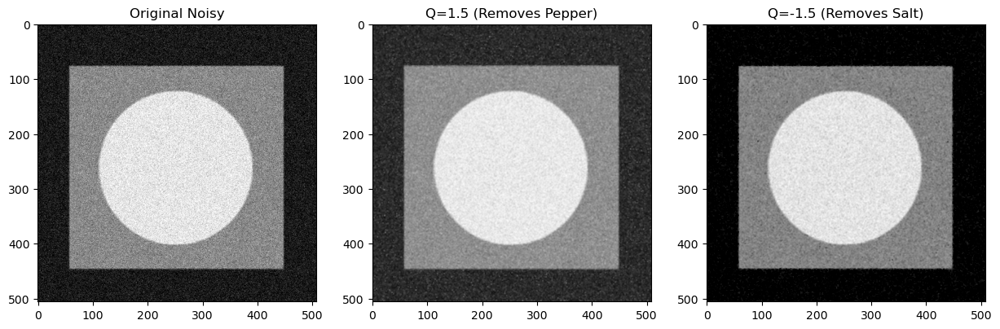

In [7]:


def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed, cmap='gray'), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed, cmap='gray'), plt.title('Q=-1.5 (Removes Salt)')
plt.show()


## **Median Filter**

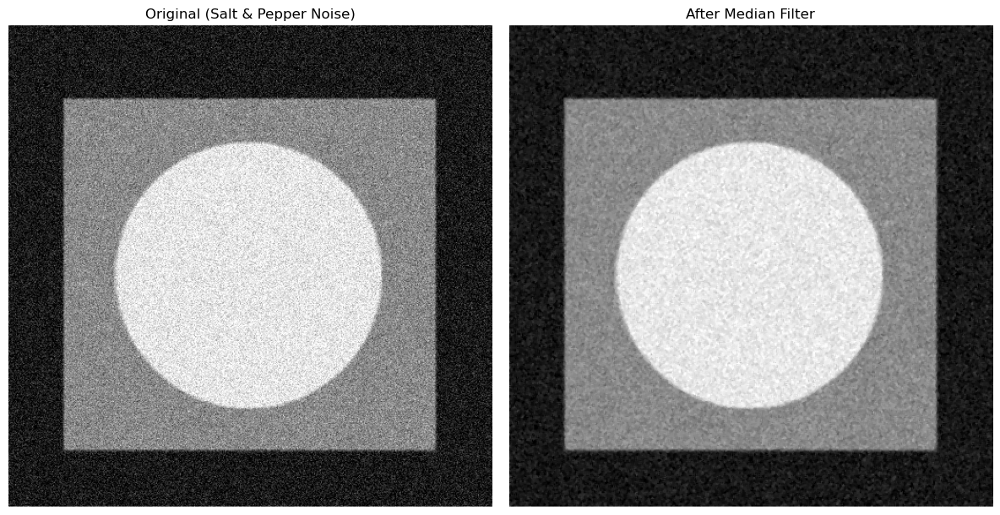

In [8]:



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result, cmap='gray'), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Max and Min Filter**

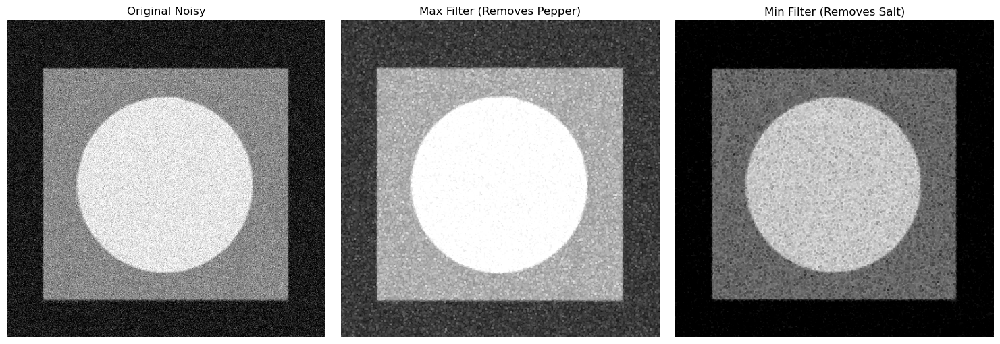

In [9]:


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss



# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))

plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter, cmap='gray'), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter, cmap='gray'), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Mid-Point Filtering**

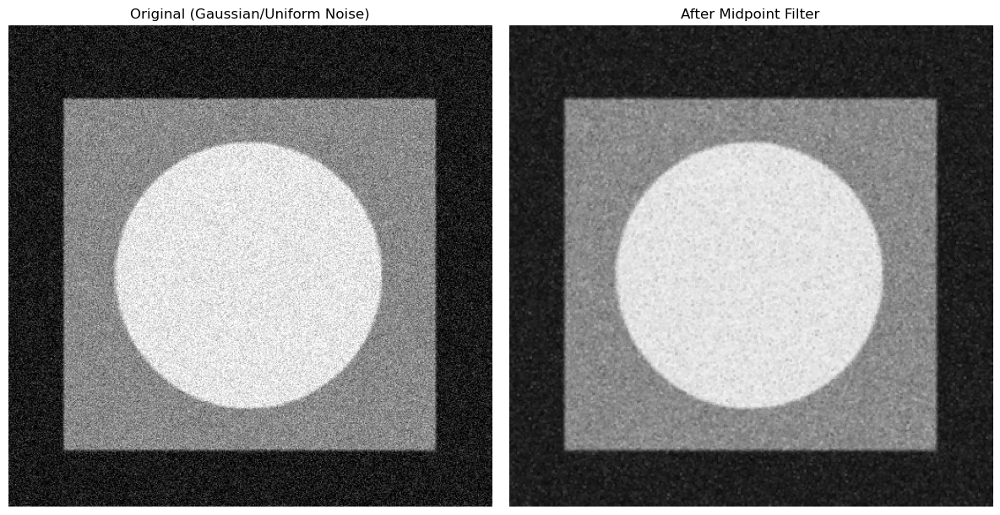

In [10]:

def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Gaussian/Uniform Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()


# Task: Applying the Filters on a Colored Image

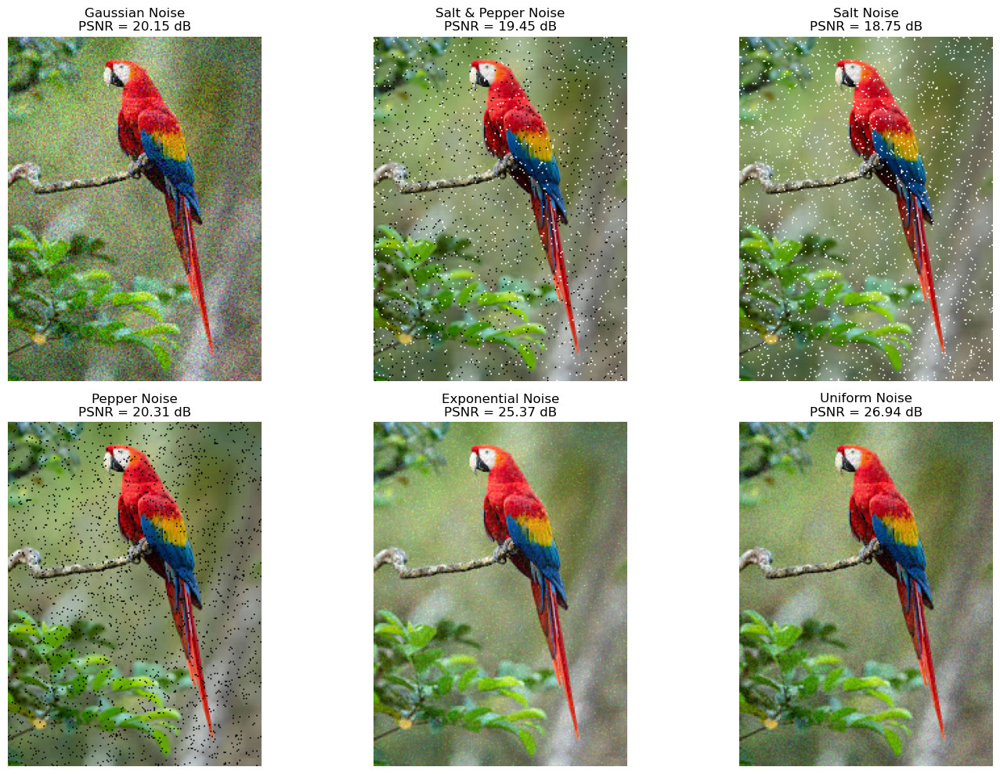

In [11]:
colorPath = '../lab5/images/images.jpeg'
img_color = cv2.cvtColor(cv2.imread(colorPath), cv2.COLOR_BGR2RGB)

np.random.seed(0)

def add_noise_color(image, noise_type):
    row, col, ch = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col, ch))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type in ("salt_pepper", "salt", "pepper"):
        amount = 0.04
        s_vs_p = {"salt_pepper": 0.5, "salt": 1.0, "pepper": 0.0}[noise_type]
        noisy = np.copy(image)

        r = np.random.rand(row, col)
        noisy[r < amount * s_vs_p] = 255                         
        noisy[(r >= amount * s_vs_p) & (r < amount)] = 0         
        return noisy

    elif noise_type == "exponential":
        expo = np.random.exponential(scale=10.0, size=(row, col, ch))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col, ch))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)


def psnr(result):
    return cv2.PSNR(img_color, result)

def show_row(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1), plt.imshow(im), plt.title(t), plt.axis('off')
    plt.tight_layout()
    plt.show()



c_gauss = add_noise_color(img_color, "gaussian")
c_sp = add_noise_color(img_color, "salt_pepper")
c_salt = add_noise_color(img_color, "salt")
c_pepper = add_noise_color(img_color, "pepper")
c_expo = add_noise_color(img_color, "exponential")
c_uni = add_noise_color(img_color, "uniform")


images = [c_gauss, c_sp, c_salt, c_pepper, c_expo, c_uni]
titles = ['Gaussian Noise', 'Salt & Pepper Noise', 'Salt Noise', 'Pepper Noise', 'Exponential Noise', 'Uniform Noise']

plt.figure(figsize=(15, 10))
for i, (im, t) in enumerate(zip(images, titles)):
    plt.subplot(2, 3, i + 1), plt.imshow(im), plt.title(f'{t}\nPSNR = {psnr(im):.2f} dB'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Arithmetic Mean** (Colored)

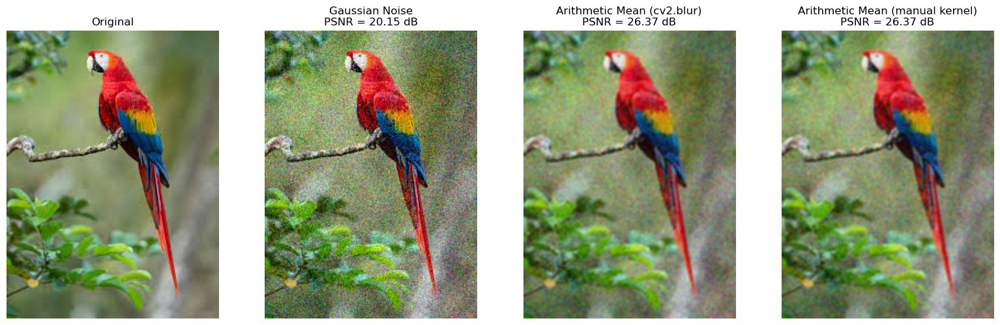

In [12]:
mean_builtin = cv2.blur(c_gauss, (3, 3))

kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
mean_manual = cv2.filter2D(c_gauss, -1, kernel)

show_row([img_color, c_gauss, mean_builtin, mean_manual],
         ['Original',
          f'Gaussian Noise\nPSNR = {psnr(c_gauss):.2f} dB',
          f'Arithmetic Mean (cv2.blur)\nPSNR = {psnr(mean_builtin):.2f} dB',
          f'Arithmetic Mean (manual kernel)\nPSNR = {psnr(mean_manual):.2f} dB'],
         figsize=(16, 5))


## **Geometric Mean** (Colored)

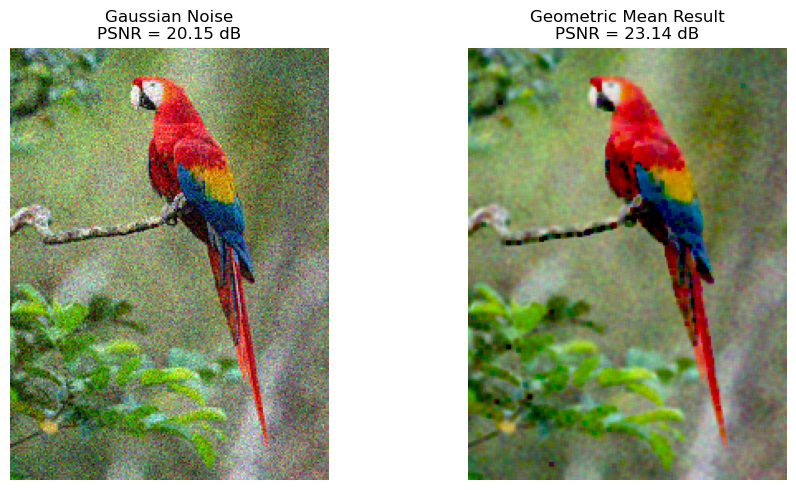

In [13]:
geo_color = geometric_mean_filter(c_gauss, kernel_size=3)

show_row([c_gauss, geo_color],
         [f'Gaussian Noise\nPSNR = {psnr(c_gauss):.2f} dB',
          f'Geometric Mean Result\nPSNR = {psnr(geo_color):.2f} dB'],
         figsize=(10, 5))


## **Harmonic Mean Filter** (Colored)

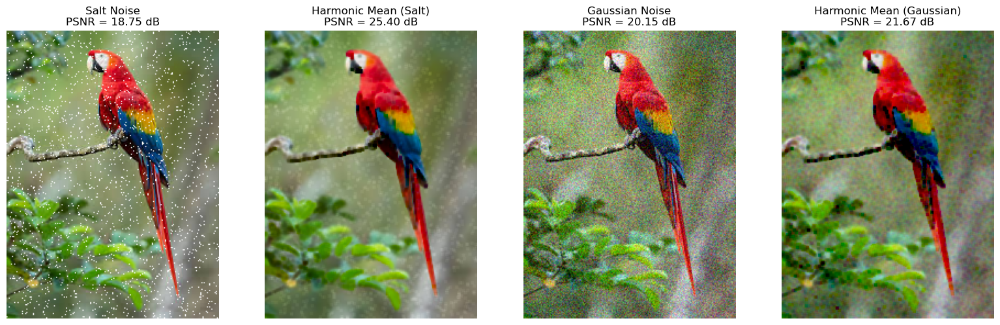

In [14]:
harm_salt = harmonic_mean_filter(c_salt, kernel_size=3)
harm_gauss = harmonic_mean_filter(c_gauss, kernel_size=3)

show_row([c_salt, harm_salt, c_gauss, harm_gauss],
         [f'Salt Noise\nPSNR = {psnr(c_salt):.2f} dB',
          f'Harmonic Mean (Salt)\nPSNR = {psnr(harm_salt):.2f} dB',
          f'Gaussian Noise\nPSNR = {psnr(c_gauss):.2f} dB',
          f'Harmonic Mean (Gaussian)\nPSNR = {psnr(harm_gauss):.2f} dB'],
         figsize=(16, 5))


## **Contra - Harmonic Mean Filter** (Colored)

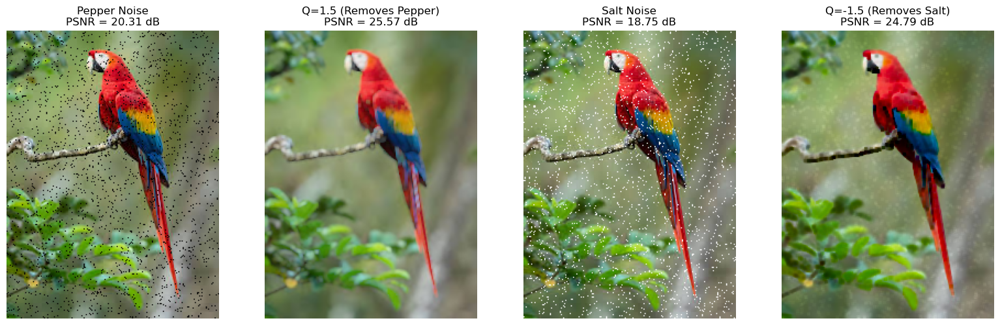

In [15]:
pepper_removed_c = contra_harmonic_mean(c_pepper, kernel_size=3, Q=1.5)

salt_removed_c = contra_harmonic_mean(c_salt, kernel_size=3, Q=-1.5)

show_row([c_pepper, pepper_removed_c, c_salt, salt_removed_c],
         [f'Pepper Noise\nPSNR = {psnr(c_pepper):.2f} dB',
          f'Q=1.5 (Removes Pepper)\nPSNR = {psnr(pepper_removed_c):.2f} dB',
          f'Salt Noise\nPSNR = {psnr(c_salt):.2f} dB',
          f'Q=-1.5 (Removes Salt)\nPSNR = {psnr(salt_removed_c):.2f} dB'],
         figsize=(16, 5))


## **Median Filter** (Colored)

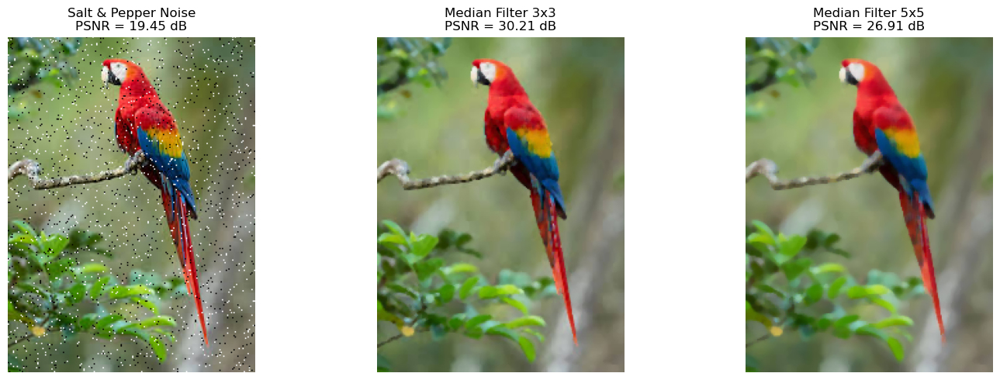

In [16]:
median_3 = cv2.medianBlur(c_sp, 3)
median_5 = cv2.medianBlur(c_sp, 5)

show_row([c_sp, median_3, median_5],
         [f'Salt & Pepper Noise\nPSNR = {psnr(c_sp):.2f} dB',
          f'Median Filter 3x3\nPSNR = {psnr(median_3):.2f} dB',
          f'Median Filter 5x5\nPSNR = {psnr(median_5):.2f} dB'])


## **Max and Min Filter** (Colored)

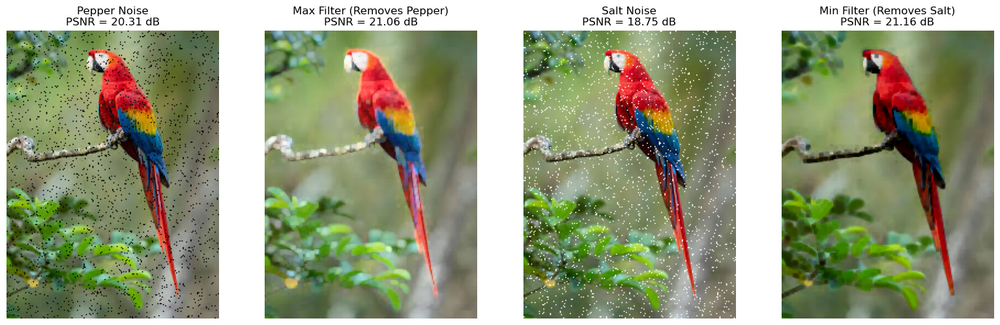

In [17]:
kernel = np.ones((3, 3), np.uint8)

max_color = cv2.dilate(c_pepper, kernel)

min_color = cv2.erode(c_salt, kernel)

show_row([c_pepper, max_color, c_salt, min_color],
         [f'Pepper Noise\nPSNR = {psnr(c_pepper):.2f} dB',
          f'Max Filter (Removes Pepper)\nPSNR = {psnr(max_color):.2f} dB',
          f'Salt Noise\nPSNR = {psnr(c_salt):.2f} dB',
          f'Min Filter (Removes Salt)\nPSNR = {psnr(min_color):.2f} dB'],
         figsize=(16, 5))


## **Mid-Point Filtering** (Colored)

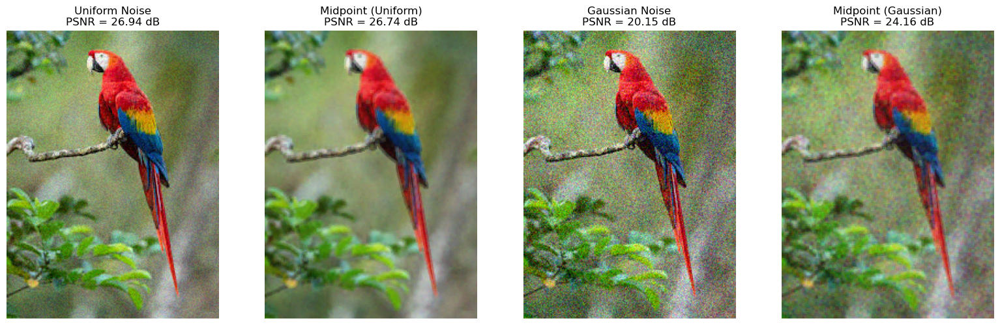

In [18]:
mid_uni = midpoint_filter(c_uni, kernel_size=3)
mid_gauss = midpoint_filter(c_gauss, kernel_size=3)

show_row([c_uni, mid_uni, c_gauss, mid_gauss],
         [f'Uniform Noise\nPSNR = {psnr(c_uni):.2f} dB',
          f'Midpoint (Uniform)\nPSNR = {psnr(mid_uni):.2f} dB',
          f'Gaussian Noise\nPSNR = {psnr(c_gauss):.2f} dB',
          f'Midpoint (Gaussian)\nPSNR = {psnr(mid_gauss):.2f} dB'],
         figsize=(16, 5))


## **Summary** (PSNR in dB, higher is better)

In [19]:
noisy_images = {'Gauss': c_gauss, 'S&P': c_sp, 'Salt': c_salt,
                'Pepper': c_pepper, 'Expo': c_expo, 'Uniform': c_uni}

filters = {
    'Arithmetic Mean': lambda im: cv2.blur(im, (3, 3)),
    'Geometric Mean':  lambda im: geometric_mean_filter(im, 3),
    'Harmonic Mean':   lambda im: harmonic_mean_filter(im, 3),
    'Contra-Harm Q=1.5':  lambda im: contra_harmonic_mean(im, 3, Q=1.5),
    'Contra-Harm Q=-1.5': lambda im: contra_harmonic_mean(im, 3, Q=-1.5),
    'Median':          lambda im: cv2.medianBlur(im, 3),
    'Max':             lambda im: cv2.dilate(im, np.ones((3, 3), np.uint8)),
    'Min':             lambda im: cv2.erode(im, np.ones((3, 3), np.uint8)),
    'Midpoint':        lambda im: midpoint_filter(im, 3),
}

print(f"{'Filter':<20}" + ''.join(f'{n:>9}' for n in noisy_images))
print(f"{'(no filter)':<20}" + ''.join(f'{psnr(im):>9.2f}' for im in noisy_images.values()))
for name, f in filters.items():
    print(f'{name:<20}' + ''.join(f'{psnr(f(im)):>9.2f}' for im in noisy_images.values()))


Filter                  Gauss      S&P     Salt   Pepper     Expo  Uniform
(no filter)             20.15    19.45    18.75    20.31    25.37    26.94
Arithmetic Mean         26.37    25.92    24.99    25.80    25.65    28.51
Geometric Mean          23.14    15.13    25.94    12.33    26.19    26.06
Harmonic Mean           21.67    14.11    25.40    11.41    25.53    24.80
Contra-Harm Q=1.5       22.35    17.62    15.43    25.57    22.71    24.99
Contra-Harm Q=-1.5      20.62    14.06    24.79    11.38    24.92    23.96
Median                  25.63    30.21    30.14    30.07    26.84    28.34
Max                     14.82    12.00     9.65    21.06    16.34    19.11
Min                     15.02    13.68    21.16    11.20    22.20    19.07
Midpoint                24.16    17.05    16.21    17.62    23.13    26.74
